# Imports

In [1]:
//> using dep io.github.quafadas::scautable-almond:0.0.46
//> using dep io.github.quafadas::dedav4s_notebook:0.10.8



import $cp.^.resources

import io.github.quafadas.table.*
import io.github.quafadas.scautable.notebook.{*, given}
import io.github.quafadas.plots.SetupVegaNotebook.{*, given}
import io.circe.syntax.*

## Data Acquisition

In [2]:


lazy val data = CSV.resource("titanic.csv").toVector

data.display()

+-----+-------------+----------+--------+-----------------------------------------------------+--------+------------+-------+-------+------------------+---------+------------+----------+
|     | PassengerId | Survived | Pclass | Name                                                | Sex    | Age        | SibSp | Parch | Ticket           | Fare    | Cabin      | Embarked |
+-----+-------------+----------+--------+-----------------------------------------------------+--------+------------+-------+-------+------------------+---------+------------+----------+
| 0   | 1           | false    | 3      | Braund, Mr. Owen Harris                             | male   | Some(22.0) | 1     | 0     | A/5 21171        | 7.25    | None       | Some(S)  |
| 1   | 2           | true     | 1      | Cumings, Mrs. John Bradley (Florence Briggs Thayer) | female | Some(38.0) | 1     | 0     | PC 17599         | 71.2833 | Some(C85)  | Some(C)  |
| 2   | 3           | true     | 3      | Heikkinen, Miss. Laina                              | female | Some(26.0) | 0     | 0     | STON/O2. 3101282 | 7.925   | None       | Some(S)  |
| 3   | 4           | true     | 1      | Futrelle, Mrs. Jacques Heath (Lily May Peel)        | female | Some(35.0) | 1     | 0     | 113803           | 53.1    | Some(C123) | Some(S)  |
| 4   | 5           | false    | 3      | Allen, Mr. William Henry                            | male   | Some(35.0) | 0     | 0     | 373450           | 8.05    | None       | Some(S)  |
| …   | …           | …        | …      | …                                                   | …      | …          | …     | …     | …                | …       | …          | …        |
| 886 | 887         | false    | 2      | Montvila, Rev. Juozas                               | male   | Some(27.0) | 0     | 0     | 211536           | 13.0    | None       | Some(S)  |
| 887 | 888         | true     | 1      | Graham, Miss. Margaret Edith                        | female | Some(19.0) | 0     | 0     | 112053           | 30.0    | Some(B42)  | Some(S)  |
| 888 | 889         | false    | 3      | Johnston, Miss. Catherine Helen "Carrie"            | female | None       | 1     | 2     | W./C. 6607       | 23.45   | None       | Some(S)  |
| 889 | 890         | true     | 1      | Behr, Mr. Karl Howell                               | male   | Some(26.0) | 0     | 0     | 111369           | 30.0    | Some(C148) | Some(C)  |
| 890 | 891         | false    | 3      | Dooley, Mr. Patrick                                 | male   | Some(32.0) | 0     | 0     | 370376           | 7.75    | None       | Some(Q)  |
+-----+-------------+----------+--------+-----------------------------------------------------+--------+------------+-------+-------+------------------+---------+------------+----------+
… 881 more rows [891 rows × 12 columns]

# Plotting

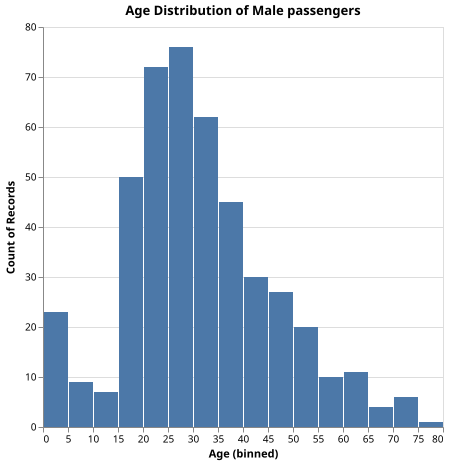

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEySYUqUMSSCGcCGgDaoAApIIEOLLJwATgEllaAIxKAyg1vEapJ6gBmOpZKJlCC5gaoAMxKAHJICHBoIABCtkgMssoKAAQAsraUOQDyAO5WOQASSLa2NAbucAAeyciCSUoAgjZoAEy97jRMbjguITWwaAAMSgAqNFAA1nCYyZ0EAKw5vc7OAOzOiiAAYjVJqHuUvRtKAMJITDTyqLIMgoJKAKIITDXLfiA3CAAL4KUwRKw2Bx+G6AzzeXxoQKCYIgULhCxoGIgeKJNbvKy5ApFADqNHeNASVSstgAnkc3M1WjoOiBuucorC3EMRtNxrZJqgZiB5ksVskonsogAWDZTI6nWznAAclCmsPuj2er3eXx+fzgAKBoPBFkhdkcaDE7nhPkNSKCcBCYQiWLiCXOIDybHSsiJhRyACkPQ1AUz0G1Wey0DqPoCeaMhfzBcLRctVugolEpsq9nsFWc0KrZcrsZqnjG3nHvr9bP9kgBFEFgtEQ6wWvx7G1eO1+ZGo9Gu1CuHEe5J5KD3Wz0Wn+orzBBsGdBhnhkCRo7R1AbaWDYaJ4VmAUwPkihbp5L7aViKIFpVoDbOSjKsTXO4PCvoT7Xo41g1G5tTUsdtoSLbsEXtAJHWdDFImxXFPTMFEZD9fJzEwOwigAcTYCB1ByAAZOA5BqJxGhaCMWU3HpUAGeN9zdVtjzGM8xQzEAZQATk4qZOLvc4djVPYNQ-bUqz1Wt63QY0WzMM0QMtYdsQ8HtESglEnTRF1MWid08WkjIsjsKA2CWOccjJCkqUqGl6XI5l2mogThW5BikyYlM5nPcV0HWDYih2R9+KLNURK1StdRAP860gwFANbeSoUU5xdzhVTIP7TTBx0+Cx18ozbAsORzM6AqICDNgYCQeR7MoxyuhoqJOL3Xlh2TE9ty8tiJWlPYc16YLoifXphPfcKXnEqL9RigCTQS4Ckr8fZwN7B0NJgodcv0kAACUFidNC8MwnJPgYGxZFZRkKPXKiGoElrE1So9BRHNMfI45VejEDYBqURUBM4yhnDfEByzEyLoqkkAmzmuSFo7FxlRWtTMFsPQNp0uiEOSSzhASCBzNuKrbHacrTvOy61w3O6IrjVzWsPCYOtTbz2N6aVpUlW8-sLJSxs-WMJP-ZIZKA81QNokcVIgvtoK02C+j0z1jlpWQLtnfIA0DXC4BwGAV1qm76rZRquQTU9nuZrqL3QXompfDZBq+-nweraaodF+bxcU-pkcg1H0flocsby1I4H0doNeJQikFKJVZCgSnrupk2OVS+mD3a083rZ6UX045VBucMtROSAARDYxF-d3Ys9uHvb8dm-b8AOsu0yIR2x6TBDYHA7HM3HKQQHJZhgNgEDwORV2T27U76JH6IZrP3Jzy9i72ZVC55+9on8sLPzZKuhZmkX4vrhTG67NKZbWgd28YruppoWxzMVJVlByIm4Cqphp4cqMaKC0XpnDyVtWI2xAF9KIhxt7nEuP0fertj5Q1uGfNsi157N1vm3BWbVRzbWOD6TAmQDrRyJjUUmOROjtCaNVZQdg-51QAecZwzVgGMUtorcB71WGcTlE7G8Ltki3Dtp-a4Yj8zINrmgxKCNoguVtGpTKGM4JK2SLMNgygfRsH8P4cyBEdDsEYUbZhtMHoWyZtnVmPVOI7CPicXmlxlR8IXmDMxU1JLSNhuguR0CsHqTvrgzuocACqaNYCeGIbkMucgih5GqnoQQJ1jEpy3NKFy5t3KcJXtY9AJhbg5H2GIKYMCHE7xGpQPYvQcxCImhDGuAJUHeNkRLGU-jlFB0xmo9AJJ4BIC0ahaOnxlClFIlUFJs8txiGtOwrJlicndXQLcSgnQAqyj2HxWBLgpiUEQe4yGXjZI+NaVyRRGU5bZQ7t0r0cBaT901kUYZFBbAVUsHrCZxsty9AXhnFi2SWaLLRAUopUxpSDU+kDPqrjS51Ldp4xpMj4atJmdLVaAScFDmCdtSobBBCkEKsVB5VCaF0LsCUCAiwagfNMagaUdFfl4P+dbHh69nGDR+rUoBBzZpHJaYpSU-jW4qIfqHeJiRSEBmqGrFAhtUmAMmgyxmzEFkQK+nmQa8Dei2M5ZNblwjEUNyxD8s5st1qdNUfgz09w1bmU+LYC6eFP7E1JtSpyfQpaZKVZ5bh7FVmbACs4H64LQo6vqfC0+zSkWKU5u0i599dKWuSAAaXSHAXR5lR7ES0bYV1NNYXmLmcqgFECuLXG5mUuBz4XGhrhcLJZBqL5oGvLGs1lyRXbR2mwKEBMiWDypNrGANUwwz0+fKyKirl7Fvem4SgyyCCrOlAFTkYhJEVpCuqGtUieVi0bbSq+qKlFxtwVtT0RE1aEujmXKw9Rc1z3zbMkcTKfUSj6pKUp-0XB703R4ut0MG0YNpWwg95zW3xpPSLBISBqrmQAJpsAYGafwt6txAIZXRJ9q9bbTN+muyWlAV3atBjCrlDT9WRsNduKWJrsHCoTY-MwOokBEnQsdQMDAqo5FiDQckbBkM0X3Zkp68zXq5I4s4EpWrHZbOiIDMQuY9n3r1dJf9ciOXXzRR0ttdHQ6xFwqUIhMAo4Bj2rAMZ9wMI5tlZMmiOwC1erAZhtkBBF05Hti+DVz5v1KbiuR3dGxTnpVNYEzF1zih4SYEZx57ZBDE0wJ-H0F1hAIb4+cb6dnl4icBbsTkvFBpiCfJxDZdE3HoBSNmau4b62+YA5XQVaMMU6SxZ6EkbBcUXRfkSyoZ0TxWdHecVDnrJ3MvYrw3qg1OS7NqaDINW6I28qjTCY1gWaPmvbZ6XTpAPhEvibIGQehLPDv-m62iqozZuXs1YwFX1Csef6IRkrJHKugxUxLYpLbgs5WuThTRpQnjMaOgGPtw9jjvzsOeFLLgPVuVhNkuijnbidG2ClMF0nryUDYQ93VpHlPVbkfl97DWLWP25OkWk1VKSDIDMUQqVgIe0XpYN0Bl3VXTM2bhzV93iNY6e00+bFHBHqcPaBoJ1zqi1HqOZGysg6Q5BSM-RYxNlCrF6zS2UBbH3zKnexKIYhCvlo-agUslBeoKdBqWCrv667HMUmIdO1H0W0fA9JRYrWyD-Ys0UMXOgyKHaYcd9OmTsSw+Gz1KFW9cMVIx1zsNluXs24CzfB3q28HE4wqM6cJVBBMDsHFzodOBvnaG8+vJwK9jFKkxHy4VSalEfGo939vOd0AemXVwOWmndeng7WOAix3fHSwmD3C+eFWZI18qzLLP8tF38uzDY0K6-c4b3HvwcmCeO+ubcJU5gJWPPtfoOLwZEihiukdvNrD0tM5VdOygJgigylt8GwNpYvPY583z3dfU1-J470mp4veiUABqTwicsgAAXnTs7LMuhpriHpmIGvAcGthgpvXifDju-gBgcF-lpiHNtIGFYIsH9kSm4BhHrBULcJ4LIGwKUHTlEAzoXpflrsIisnftArsEXDssgYvqgW-k3nIlKFgfGjgZ6DipoiVD8LYDrEGAdifn7nmrZrMhdlfuxDOsULOkUClLmGzgblKJNrXgLFwR7MvmgHsHbstknu3hvjABIZQTgPBj3D2tHJ0LYXhLikPirsdpAQymPt6o5l9MqPKNJilMbjuMVtHrWtwY3l7B-gnmikKt-tcnLtYPouHDQXQUvAwbASAM4MUu+rzJXMbtWnoUgj+twVbnyp2CivbppmBtct6ISEQTQGQJ4B-FKsBBAWdukRhqJjKMqMDPro4vhqbscDkFhFKBbqUUYRcPulUUeptNcsQdVGmnokSvYNoEOjISYsdgXp0TAcXhxNKLYjmB5s4nPi-k9mUQtsYUtontUcerUfBuoFttHDtEgFVAgE8FUEgDQAgMPuOo

res3_1: scala.Unit | os.Path = ()

In [3]:
val histogram = VegaPlot.fromResource("histogram.vl.json")

histogram.plot(
  _.data.values := data.filter(_.Sex == "male").asJson,
  _.title := s"Age Distribution of Male passengers",
  _.encoding.x.field := "Age",
  _.encoding.x.bin.step := 5
)


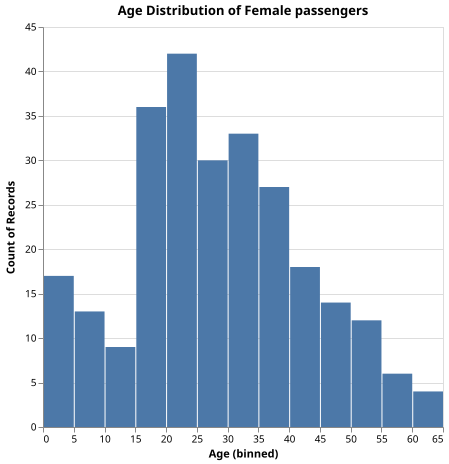

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEySYUqUMSSCGcCGgDaoAApIIEOLLJwATgEllaAExKAyg1vEapJ6ky2ekomUILmBqgAjEoAckgIcGggAMIMCDTWEAoABACythCU2QBSbDCy2QBCtkjKgnAAntkAFABigmy2VlBwVbY0ZGQQ2QAqMEgNdgCUiiBucAAeSQBmiDqJSgCCNmgAzAAc7jRMbjho0SBmtrBoAAxKIzRQANZwmEkmydmRAOwArABOAGzVpILpoH6RSjOfa7XZKZJIJgZJLJfZ-WYAUQQTDBrz8KRAAF8FKZwlYbA4-PC5p5vL40AEgpdQuE9rF4ol0AAJOA0Z7PDJWHK5GgWIoAGSQGRQ7kWKzW9Vm2y5zjERxOZ1Q90uYJu2oeT1e73QbhGAHkYgRzc4irtIrdIjDnCCwVyfpQAc4-gikSjULIGIJBEpsbjbPikm5iaTdRYKXZHGgACzuOk+OB+JlwYKsiznDkJJKtBgBODBnN5ApFYpIKAARz0w15ahgLQlNEETVyE2yJjg5ZmcqW6FWyCVWx2qF2Prmx1OBd11xgd0NLzeSUikQOt12rvBqD+u0oF0RyPk6GSTr3oZxeMzUZjZPj1kTfgBaa8GazgRzLLC+bToWXIgKU5QyLIIrVtk5rQGC2QAOotJiwgQEibxtgAap28CCOkshIFUdhkEOczyqOiobCAKouD8GoLgaS76q4ICPOuJogLsyY-D8yYukooIHluJ5wjSZ7+oGwa3uGkamk+caWK+VLnDqHhfgy-i-rmAERCxcRFugcTxrYUGFNkMRPDAbAAS0mzKOWvSbLAiCkfMI4gGO6zKlOkSpnOmqLlc+o6mxxpJM4uw8bsYj7lyuy3JQtw-LchwpH6F6SSGIBhveBLJPJZgvpSSZRBcan0g+mnMiEOnsiA+kgW4SCyMoEABGwCAimKZk9rYZB6P0mC9AASqWsxuQq45UTRqB+W485ahcQUrlEa5hegJgmNkAJ-MmwICW65wSHRaXnkkADiMXSblj4ks+inFX4TqfhVP7VXmEQXA1SSVHIsjliGeTdUUKE0AAXuh9DjeRHmUd5XJ-Kl80BYxy2rqxRobugW6RbCsUuBIfyzuJF4pA6N7ZXeEaVXMBXkkpJWRLO5Xfmgyw6JY2lskB9WckkmH6O1nVA+K2TckGqjZJsyAtYRdnWcsMrQ+5nkTtRPlzQt6No4xoVY5xfy3MmtxXSAgnupQ6J8b6Z0BkGWU5dTBLRndCkJspUTqrS6mVdmXOAXpfM8nAADu9TYKZRTNL1TQACLZAA0hkZBQB1cBTNkyuTV5k4I8zWuo3qK0hZjHHOMm+zJab5tHTbEn29dTu3bGhUPW+5wft7r1sxzf41dzNLfegmHNfZth9mEsivJHJRBjQDDDM02LljQhG9av2Qjy1iBsJ0Q31K5MOq9NU72vRi3BEX6N6xxXF-D8YgUzXUSpSTaCZY3sm067rfuyVziqXTBpP2-4B7ASSD2eMeFmo0BnqCTANBkBZwolNeG78G7+QYjqHWJd2LhTEHtfGqAPTOG9HXDKGDHZf3yj-emj0XA0hZsArSoDAKDyDiAXIUBzpsBDs1LqotNiyAItkAAOtRYRNA4DiOQbDVBudzj5xRtgq+utS5JDhLcL0T9DqoH2IlZwXpyHoKkpTGSNMACKdMirt1QGQrurNUDs0EJzVhER2EGV1C4iCAizIjE6EwToZBsixxgTUWRx80F6PPnVHWFwb4aL2gCLRRDnBQiSsTdKJiHZUy-i7FudDbFqheo4kB-c2HgPQJsCAOBdAtRnoiWwggYJwXHs0eY0CpYMH6m1Qi2JOwbzAs1CwchD4qzhgo6cSMC5LVUbOBJ6AuLJR4kQ+0lADj-GMXbUxVCab5Pun-PwhiSnMPerVHmQ8QDmgAOSxxDpMEyIszIoXqBUcRMQAZSJkcObOasZof0wVqFRy5r7qMWfFHa+0za6I9JXIxp1647NyZY6xbcPa7BYkw32LDymfUqXMHA3Q7AzwQp2YQ8Quk9MwAvFo69eiYm6VYKRYzfkny5AC5GDFZkgrUXgjaXxfh-DEFC5+vlCYANflk9AlQfj7CxMivKqLDl7EYUA7FZywG808edLswjfFFBjlLCg9BZRkXGfI9W7KMGcqBZfHluD1qcRnGIFZB0Dwek2QiihSLzEEisbQmx6LO5Yr8M41xuK6qXK3mPCezVp5PKKJsbpC91B5DBKvCJEzLXnGmSjFiOC1r6zvg-ZMRDIiSttgC3ZzslUMz8MbE56q+4fUjRwiyqcwj8AAJpgi6MofVJR4idlNRNFBOds1RE1ijblwVC1lzEH8SIZaoTl1+FsqtCrUS1vobNMqarQ2939u4-FmwYDCEglWMyQyKjNGvSI-sBRlBsGwHYbIUoCgQRZWOv5U4G2AsCqoh1+t-jJmrrogElBuKZMrZQzdckA1opKtbBxGkw3NvOYHTxIxPA4AyCSslq8EAlDKBUYabAmB2EwC0WOnRn0wCaEIioCE-p1mfZgL9cjx0zWcCdG1AH7Vzs3JEMQYg5VutVKeKVG7fXNwOXWlMc192MhxS2ux+L31sGcgO+aCA-q9DpVLYRjkWpdCoqOzjP64oxNWkxFaLEFlzGSAQK4YpshpIikQ5MUJ77wrftsnJMnLzbtscmZmSmqroc1Zc2OcBtD-QaAO3qFAuhUZi+SzNFqZqRGDQXYFs6MZ8qdVoxGRDYU-F81J2DgWQD+oKYGpDSNwtlNUx4kCNzY79GgNZQGopRbVBoMoGw7wfnfrZdk6zeXi6Cexsme0S7xMQkoJ6vz0mbroFq3JndhtG0HpcZFipWqQKbFsLIayyh+CtBqLIWAsDL01jYJYZYLRSiPaFNkS7zUbscciZM8t1mZ1TYK46ri2ifhltheuqra3v51cQ34I8O3lMasAl9Dh3IwSEsefkMyvJZC2CaG4eocBMe0oaCI9HCxqWyG+1mmae1-t2vyw5z43x-g-H4tC91x1DEsT8yAWOcJ5XVZobD5Vh5FM+zevt3S+LQQMFkPQTohKZ4djBmDKRyFhAQwo-QQz-1EKdkFLIT9GWuNTmOf+mzBagf6x52Bg8xSvXjbMdD-Zbt5OHl401lTGH8WjUGAO-pXZTeWZcGVXLjPAcOeSJQTYdoHRqjLQlaDiKAuu+Cx7QEiOItHpcPihCgsB3JDkL067+maD9DSCHsbh4Ge2bzzbjiMe4-ZC4gu+bnPVQepT96tPTd4Oi492ITF3vkd4sO0kewUAwT9oTVLBIwgzNH1p6fXNWDI+gsKzje+HPn77B1HzyoMIhdrcyghsXLrs-Nd9xPwykwZ5Ly15DNsw1OTBhp5l83OXlEb95Y65vRQhiuwO0SelAPexYgun8eyGeJUwqV+PuUWHCQiY8IyF6vWzyJ2cs9QCwo84SI2FmNea6lufkOs9mYKnEDoTo+wHez8HoXo4B-mUBNa5+Hu7O2eaGueFyHCPCbAygIceGc+HYwYq8FQ0sDQ1eUSwm1ms4pB02KQmwbmvkpaC2s0EgncK2UO-eMOm2ti++8BY+raniNGIc9kUkc+oM2uGEEhky8UE2v+QGt8BCi69uXITokGy2lWPq6eLBO6sI+h0uhhIEXCMWtgumEcc+-WZA9kqWK8I6y+n+VqpifGhcAmjeGiEKGKpWS2lcDBq2WhG27uvhYWkuSOARamt+IA9g4cmAA6lQlG4w1hE6RByRk2m+jqbg5oBAAqFc6IoBuRmheSMBfg+wXsIapRnBrWP0dYzwbUtgHUM8CcYIzSmwggywfatK6aa8rYnYks50KaSAywqBH+ZucUjCBcNI1uDm9ojoPGYmneiils-RXhWhbuv8Hu+wwao+ZRqOnirQe

res4: scala.Unit | os.Path = ()

In [4]:
histogram.plot(
  _.data.values := data.filter(_.Sex == "female").asJson,
  _.title := s"Age Distribution of Female passengers",
  _.encoding.x.field := "Age",
  _.encoding.x.bin.step := 5
)